In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/digit-recognizer/sample_submission.csv
/kaggle/input/competitions/digit-recognizer/train.csv
/kaggle/input/competitions/digit-recognizer/test.csv


In [41]:
df = pd.read_csv('/kaggle/input/competitions/digit-recognizer/train.csv')

In [5]:
df.head()

,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [6]:
df.shape

(42000, 785)

In [7]:
import matplotlib.pyplot as plt

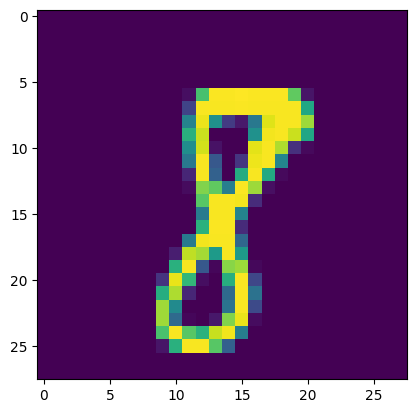

In [9]:
plt.imshow(df.iloc[18307,1:].values.reshape(28,28))

In [42]:
 x = df.drop("label", axis=1)
 y = df["label"]

# x = df.iloc[:,1:]
# y = df.iloc[:,0]

In [14]:
print(x.shape)
print(y.shape)


(42000, 784)
(42000,)


In [43]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x,y, test_size=0.2, random_state=42)

In [17]:
x_train.shape

(33600, 784)

In [21]:
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier()
knn.fit(x_train, y_train) 

# Har particular image ka baake saare images se distance nikal rhe hai 

KNeighborsClassifier()

In [23]:
import time
start = time.time()
y_pred = knn.predict(x_test)
print(time.time()-start) # just checking time because this process takes time 

10.46943974494934


In [27]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test, y_pred)

0.9648809523809524

In [44]:
# Now using PCA 
# step 1: Standarise the data

from sklearn.preprocessing import StandardScaler

scaler =  StandardScaler()

x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

# Now we have complete the mean centering of dataset

In [45]:
# PCA
from sklearn.decomposition import PCA
pca = PCA(n_components=100)

# found eigen vector and eigen values and shifted data to new coordinate axis

In [46]:
x_train_trf = pca.fit_transform(x_train)
x_test_trf = pca.transform(x_test)

In [48]:
x_train_trf.shape

(33600, 100)

In [49]:
# Now we need to  train this data

knn = KNeighborsClassifier()

knn.fit(x_train_trf, y_train)
 

KNeighborsClassifier()

In [50]:
y_pred = knn.predict(x_test_trf)

In [51]:
accuracy_score(y_test, y_pred)

0.9544047619047619

In [ ]:

 # around 95 percent : this is when we gave 100 components 

# Now we can check for how much component model accuracy will be best using loop

for i in range(1, 785):
    pca = PCA(n_components=i) 
    x_train_trf = scaler.fit_transform(x_train)
    x_test_trf = scaler.transform(x_test)

    knn = KNeighborsClassifier()

    knn.fit(x_train_trf, y_train)

    y_pred = knn.predict(x_test_trf)

    print(accuracy_score(y_test, y_pred))

In [57]:
# Visualising the data
# transforming to a 2D coordinate system
pca = PCA(n_components=2)
x_train_trf = pca.fit_transform(x_train)
x_test_trf = pca.transform(x_test)


In [58]:
x_train_trf

array([[-2.71863253, -0.48982409],
       [-0.67698015, -6.75362491],
       [-3.03323281,  6.50981624],
       ...,
       [ 2.14883643,  0.78079444],
       [ 1.05957006,  0.94767312],
       [17.70258446,  1.96188185]])

In [63]:
import plotly.express as px  # Used because of dynamic experience(if we hover over points we can see there coordinates)
y_train_trf = y_train.astype(str)
fig = px.scatter(x=x_train_trf[:,0], 
                 y=x_train_trf[:,1],
                 color=y_train_trf,
                 color_discrete_sequence=px.colors.qualitative.G10
                )
fig.show()

In [64]:
# Now transforming into 3D
pca = PCA(n_components=3);
x_train_trf = pca.fit_transform(x_train)
x_test_trf = pca.transform(x_test)

In [65]:
x_train_trf

array([[-2.71863253, -0.48982409,  1.1354966 ],
       [-0.67698015, -6.75362491, -2.33590139],
       [-3.03323281,  6.50981624,  7.49182983],
       ...,
       [ 2.14883643,  0.78079444, -0.74738774],
       [ 1.05957006,  0.94767312,  3.94973114],
       [17.70258446,  1.96188185, -4.94352837]])

In [67]:
y_train_trf  = y_train.astype(str)
fig = px.scatter_3d(
    df, x=x_train_trf[:,0], y=x_train_trf[:,1], z=x_train_trf[:,2], color=y_train_trf
)
fig.update_layout(
    margin= dict(l=20, r=20, t=20, b=20)
)
fig.show()

In [68]:
pca.explained_variance_
# Eigen values for 3D

array([40.67111198, 29.17023401, 26.74459621])

In [69]:
pca.components_
#  Eigen vector

array([[ 0.,  0.,  0., ...,  0.,  0.,  0.],
       [-0., -0., -0., ..., -0., -0., -0.],
       [ 0.,  0.,  0., ...,  0.,  0.,  0.]])

In [70]:
pca.components_.shape

(3, 784)

In [ ]:
# finding optimum no. of components required for best model accuracy